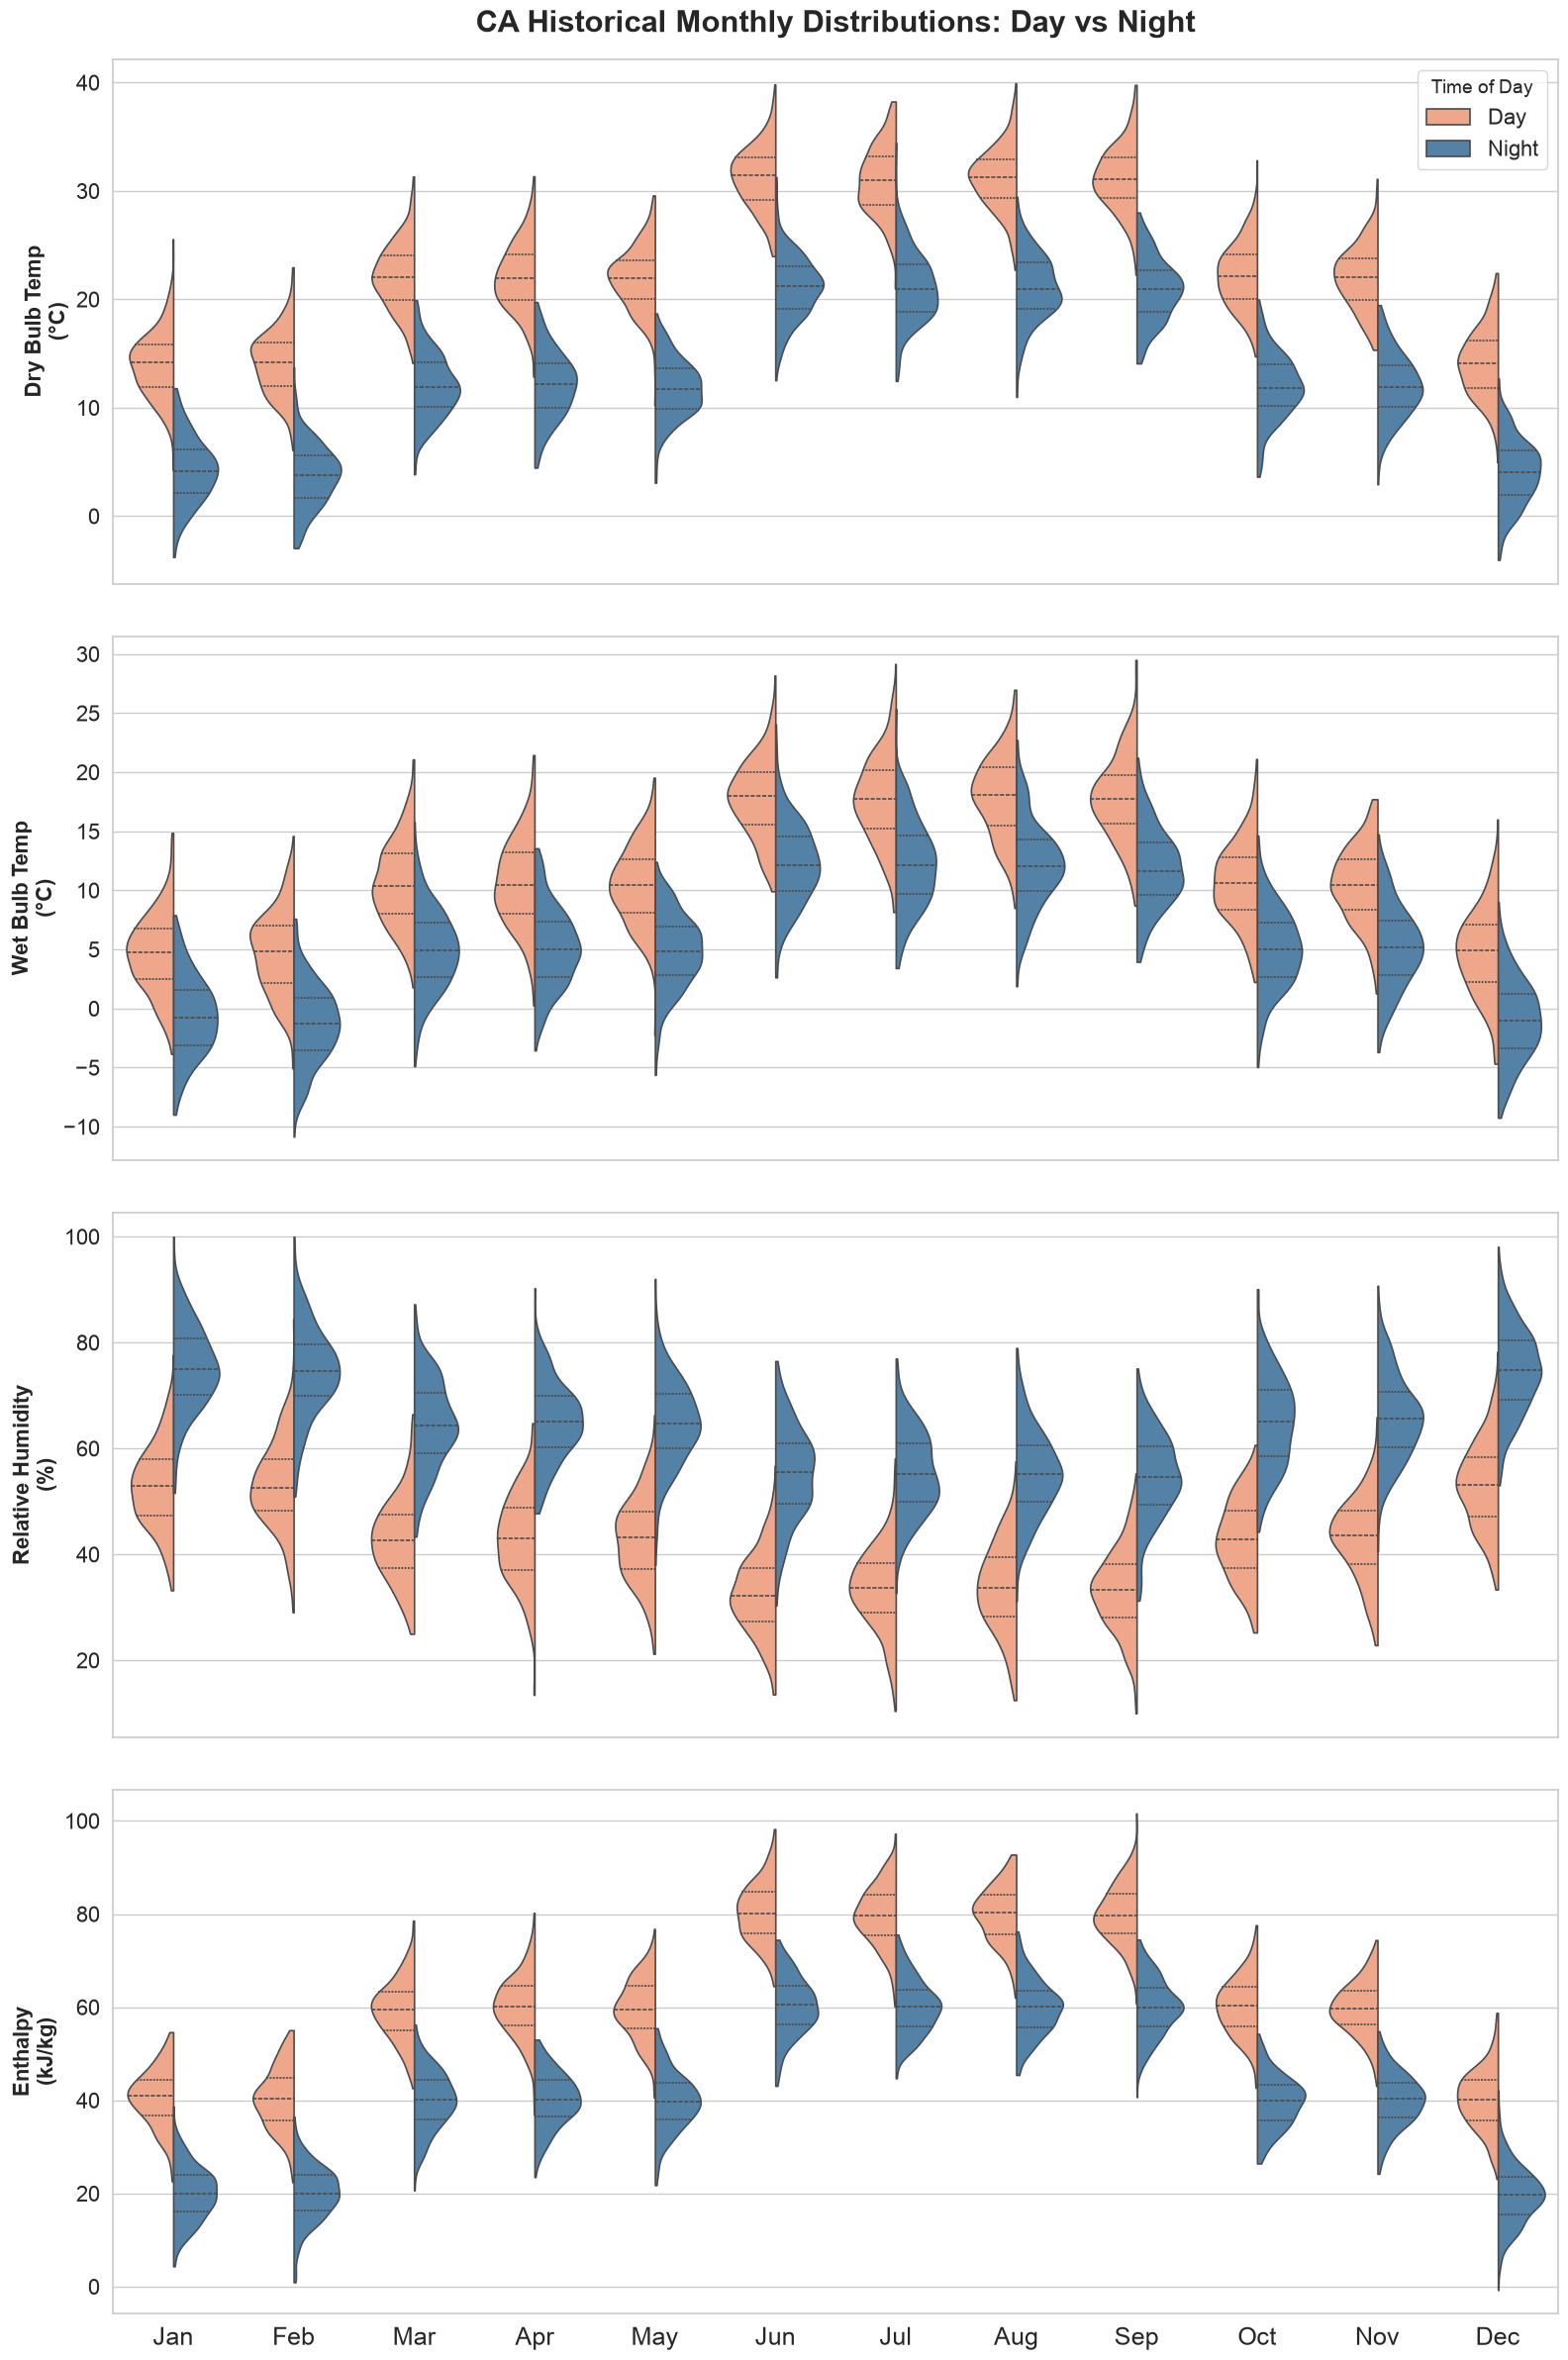

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. SETUP DUMMY CONSTANTS
# ==========================================
state_abb = "CA"

# Standard seaborn styling
sns.set_theme(style="whitegrid")

# Dictionary defining colors for Day and Night
PALETTE = {'Day': '#FFA07A', 'Night': '#4682B4'} 

# Define the 4 variables to match your request
PLOT_VARS = [
    {'col': 'T_dry',    'name': 'Dry Bulb Temp',     'unit': '°C'},
    {'col': 'T_wet',    'name': 'Wet Bulb Temp',     'unit': '°C'},
    {'col': 'RH',       'name': 'Relative Humidity', 'unit': '%'},
    {'col': 'Enthalpy', 'name': 'Enthalpy',          'unit': 'kJ/kg'}
]

# ==========================================
# 2. GENERATE DUMMY DATAFRAME (plot_df)
# ==========================================
np.random.seed(42)
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
day_night = ['Day', 'Night']

data = []
for m in months:
    for dn in day_night:
        n_samples = 300
        
        # Determine seasonal behavior
        is_summer = m in ['Jun', 'Jul', 'Aug', 'Sep']
        is_winter = m in ['Dec', 'Jan', 'Feb']
        
        # 1. Dry Bulb Temp: Higher in summer, higher during the day
        t_base = 25 if is_summer else (8 if is_winter else 16)
        t_diurnal = 6 if dn == 'Day' else -4
        t_dry = np.random.normal(t_base + t_diurnal, 3, n_samples)
        
        # 2. Relative Humidity: Generally lower during the day as temp increases
        rh_base = 45 if is_summer else (65 if is_winter else 55)
        rh_diurnal = -12 if dn == 'Day' else 10
        rh = np.random.normal(rh_base + rh_diurnal, 8, n_samples)
        rh = np.clip(rh, 10, 100) # Keep within 10% - 100%
        
        # 3. Wet Bulb Temp: Approximated based on Dry Bulb and RH 
        # (Wet bulb approaches dry bulb as RH approaches 100%)
        wet_bulb_depression = (100 - rh) / 5.0
        t_wet = t_dry - wet_bulb_depression + np.random.normal(0, 0.5, n_samples)
        t_wet = np.minimum(t_wet, t_dry) # Wet bulb cannot exceed dry bulb
        
        # 4. Enthalpy: Total heat content (depends heavily on temp and moisture)
        # Higher in summer and day
        enth_base = 65 if is_summer else (25 if is_winter else 45)
        enth_diurnal = 15 if dn == 'Day' else -5
        enthalpy = np.random.normal(enth_base + enth_diurnal, 6, n_samples)
        
        df_temp = pd.DataFrame({
            'Month': [m] * n_samples,
            'Day_Night': [dn] * n_samples,
            'T_dry': t_dry,
            'T_wet': t_wet,
            'RH': rh,
            'Enthalpy': enthalpy
        })
        data.append(df_temp)

plot_df = pd.concat(data, ignore_index=True)

# Make Month a categorical variable so it plots in chronological order
plot_df['Month'] = pd.Categorical(plot_df['Month'], categories=months, ordered=True)

# ==========================================
# 3. YOUR EXACT PLOTTING CODE
# ==========================================
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(16, 24), sharex=True)
            
for idx, var_info in enumerate(PLOT_VARS):
    ax = axes[idx]
    
    sns.violinplot(
        data=plot_df, 
        x='Month', 
        y=var_info['col'], 
        hue='Day_Night', 
        split=True,            
        inner="quartile",      
        palette=PALETTE,
        ax=ax,
        linewidth=1.2,
        cut=0                  
    )
    
    # Using \n to stack name and unit so it doesn't push the plot inwards
    ax.set_ylabel(f"{var_info['name']}\n({var_info['unit']})", fontweight='bold', fontsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.tick_params(axis='x', labelsize=18)
    ax.set_xlabel('') 
    
    if idx == 0:
        ax.legend(title='Time of Day', fontsize=16, title_fontsize=14, loc='upper right')
        ax.set_title(f"{state_abb} Historical Monthly Distributions: Day vs Night", fontweight='bold', fontsize=22, pad=20)
    else:
        if ax.get_legend() is not None:
            ax.get_legend().remove()

plt.tight_layout()
plt.subplots_adjust(hspace=0.1) 
plt.show()